# Практическая работа №3
## Подземная гидромеханика · Вариант 5

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.special import exp1
from scipy.stats import linregress
from IPython.display import display, Markdown

%matplotlib inline
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.22,
    'figure.dpi': 125,
    'savefig.dpi': 160,
})
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda x: f'{x:.6g}')

SECOND_PER_DAY = 86400.0
MPA = 1e6
MPAS = 1e-3
MICRON2 = 1e-12
CM = 1e-2
LITRE = 1e-3
# На стр. 9 учебник определяет 1 Дарси через перепад 0,1 МПа.
# Это соответствует принятому в пособии округлению 1 Д = 10^-12 м².
DARCY_BOOK = 1e-12
DARCY_STANDARD = 9.869233e-13  # только для оценки влияния другого соглашения
P_ATM_BOOK = 0.1 * MPA       # как в примере 5.3 на стр. 48
results = {}

def answer(text):
    display(Markdown('**Ответ.** ' + text))

def show_table(rows, columns):
    display(pd.DataFrame(rows, columns=columns))

print(f'Вариант 5 · Python {sys.version.split()[0]}')
print('Расчёт в СИ; 1 сут = 86400 с; 1 мкм² = 10⁻¹² м².')

Вариант 5 · Python 3.12.14
Расчёт в СИ; 1 сут = 86400 с; 1 мкм² = 10⁻¹² м².


## Исходные данные и места в книге

| Задача | Таблица / страница исходных данных | Формулы и пояснения | Пример |
|:--|:--|:--|:--|
| 1.1 | П 1.1, стр. 61 | (1), стр. 7 | стр. 45 |
| 2.1 | П 2.1, стр. 62 | (3), (8), стр. 7, 10; критерий стр. 36 | стр. 45 |
| 3.1 | П 3.1, стр. 68 | (13), стр. 11 | стр. 45 |
| 3.7 | П 3.7, стр. 74 | (17), (18), стр. 12–13 | стр. 45–46 |
| 4.1 | П 4.1, стр. 77 | (19), (27), стр. 13, 15 | стр. 47 |
| 5.3 | П 5.3, стр. 81 | (40), (41), стр. 18 | стр. 47–48 |
| 6.1 | П 6.1, стр. 82 | (48), стр. 20; рис. 1П, стр. 100 | стр. 48 |
| 7.1 | П 7.1, стр. 84 | (59), (61), стр. 24; рис. 2П, стр. 100 | стр. 48–49 |
| 8.1 | П 8.1 и П 8.2, стр. 87 | (82)–(85), стр. 28–29 | стр. 49–50 |
| 9.1 | П 9.1–П 9.3, стр. 94–96 | (70), (75), (77)–(79), стр. 26–28 | стр. 50–52 |
| 10.1 | П 10.1, стр. 97 | (87), стр. 31 | стр. 52 |

Исходные данные каждого задания задаются в отдельной ячейке. Расчёты не используют числа из демонстрационных примеров вместо данных варианта.

## 1.1. Пористость фиктивного грунта

**Дано:** угол укладки частиц $\theta=64^\circ$ (табл. П 1.1, стр. 61).

> «Для фиктивного грунта коэффициенты пористости и просветности могут быть определены по формулам Слихтера» (стр. 7).

$$m=1-\frac{\pi}{6(1-\cos\theta)\sqrt{1+2\cos\theta}}.\qquad (1)$$

Угол переводим из градусов в радианы для вычисления косинуса. Формула даёт долю единицы; в процентах это $100m$.

In [2]:
theta_deg_11 = 64.0
theta_11 = np.deg2rad(theta_deg_11)
m_11 = 1 - np.pi / (6 * (1 - np.cos(theta_11)) * np.sqrt(1 + 2 * np.cos(theta_11)))
show_table([
    ['θ', theta_deg_11, 'град'],
    ['m', m_11, 'доля единицы'],
    ['100m', 100 * m_11, '%'],
], ['Величина', 'Значение', 'Единица'])
results['1.1'] = f'm = {100*m_11:.3f} %'
answer(f'Пористость фиктивного грунта **{100*m_11:.3f} %** ($m={m_11:.6f}$).')

,Величина,Значение,Единица
0,θ,64,град
1,m,0.319471,доля единицы
2,100m,31.9471,%


**Ответ.** Пористость фиктивного грунта **31.947 %** ($m=0.319471$).

## 2.1. Закон фильтрации жидкости

**Дано:** $r=2{,}5$ см; $k=2{,}8$ Дарси; $m=10\%$; $Q=2$ л/мин;
$\mu=26$ мПа·с; $\rho=670$ кг/м³ (табл. П 2.1, стр. 62).

По формулам (3) и (8):
$$F=\pi r^2,\qquad w=\frac QF,\qquad \nu=\frac\mu\rho,$$
$$\mathrm{Re}_{\mathrm{Щ}}=\frac{10}{m^{2{,}3}}\frac{w\sqrt{k}}{\nu}.\qquad (8)$$

> «При решении задач раздела 2 критическое значение числа Рейнольдса по Щелкачеву принять равным 1, по Миллионщикову – 0,2» (стр. 36).

Как в примере задачи 2.1, используем **критерий Щелкачёва**: при $\mathrm{Re}<1$ закон линейный; при превышении принятого порога закон Дарси неприменим.
В основном расчёте принимаем используемое в книге округление $1\,\text{Д}=10^{-12}$ м² (определение на стр. 9).

In [3]:
r_21 = 2.5 * CM
k_21 = 2.8 * DARCY_BOOK
m_21 = 10 / 100
Q_21 = 2 * LITRE / 60
mu_21 = 26 * MPAS
rho_21 = 670.0
F_21 = np.pi * r_21**2
w_21 = Q_21 / F_21
nu_21 = mu_21 / rho_21
Re_21 = 10 / m_21**2.3 * w_21 * np.sqrt(k_21) / nu_21
Re_21_standard = Re_21 * np.sqrt(DARCY_STANDARD / DARCY_BOOK)
show_table([
    ['Q', Q_21, 'м³/с'], ['k', k_21, 'м²'], ['m', m_21, 'доля единицы'],
    ['F', F_21, 'м²'], ['w', w_21, 'м/с'], ['ν', nu_21, 'м²/с'],
    ['Re по Щелкачёву', Re_21, 'безразмерное'],
    ['Re при стандартном переводе Дарси', Re_21_standard, 'безразмерное'],
], ['Величина', 'Значение', 'Единица'])
law_21 = 'нелинейный' if Re_21 > 1 else 'линейный'
results['2.1'] = f'Re = {Re_21:.4f} > 1; закон {law_21}'
answer(f'$\\mathrm{{Re}}={Re_21:.4f}>1$. По принятому критерию Щелкачёва закон фильтрации **{law_21}**. '
       'Использование стандартного перевода единицы Дарси этот вывод не меняет.')

,Величина,Значение,Единица
0,Q,3.33333e-05,м³/с
1,k,2.8e-12,м²
2,m,0.1,доля единицы
3,F,0.0019635,м²
4,w,0.0169765,м/с
5,ν,3.8806e-05,м²/с
6,Re по Щелкачёву,1.46059,безразмерное
7,Re при стандартном переводе Дарси,1.45101,безразмерное


**Ответ.** $\mathrm{Re}=1.4606>1$. По принятому критерию Щелкачёва закон фильтрации **нелинейный**. Использование стандартного перевода единицы Дарси этот вывод не меняет.

# --

## 3.1. Расход жидкости при одномерной фильтрации

**Дано:** $\mu=4{,}1$ мПа·с; $k=0{,}4$ мкм²; $L=150$ м;
$\Delta P=2{,}4$ МПа; $F=325$ м² (табл. П 3.1, стр. 68).

> «Расход жидкости (дебит галереи) определится по формуле» (стр. 11).

$$Q=\frac{kF}{\mu}\frac{P_{\mathrm к}-P_{\mathrm г}}{L}
=\frac{kF\Delta P}{\mu L}.\qquad (13)$$

In [4]:
mu_31 = 4.1 * MPAS
k_31 = 0.4 * MICRON2
L_31 = 150.0
dP_31 = 2.4 * MPA
F_31 = 325.0
Q_31 = k_31 * F_31 * dP_31 / (mu_31 * L_31)
show_table([
    ['Расход Q', Q_31, 'м³/с'],
    ['Расход Q', Q_31 * SECOND_PER_DAY, 'м³/сут'],
    ['Скорость фильтрации w = Q/F', Q_31 / F_31, 'м/с'],
], ['Величина', 'Значение', 'Единица'])
results['3.1'] = f'Q = {Q_31*SECOND_PER_DAY:.3f} м³/сут'
answer(f'$Q={Q_31:.9f}$ м³/с = **{Q_31*SECOND_PER_DAY:.3f} м³/сут**.')

,Величина,Значение,Единица
0,Расход Q,0.000507317,м³/с
1,Расход Q,43.8322,м³/сут
2,Скорость фильтрации w = Q/F,1.56098e-06,м/с


**Ответ.** $Q=0.000507317$ м³/с = **43.832 м³/сут**.

## 3.7. Кривая распределения давления в зоне дренирования

**Дано:** $\mu=2{,}5$ мПа·с; $k=0{,}19$ мкм²; $r_{\mathrm к}=450$ м;
$r_{\mathrm с}=10$ см; $h=14$ м; $P_{\mathrm с}=12$ МПа; $Q=180$ м³/сут
(табл. П 3.7, стр. 74).

По формуле Дюпюи (17), как в примере на стр. 45:
$$P_{\mathrm к}=P_{\mathrm с}+\frac{Q\mu}{2\pi kh}\ln\frac{r_{\mathrm к}}{r_{\mathrm с}}.$$

Распределение давления по (18):
$$P(r)=P_{\mathrm с}+\frac{P_{\mathrm к}-P_{\mathrm с}}
{\ln(r_{\mathrm к}/r_{\mathrm с})}\ln\frac{r}{r_{\mathrm с}}.$$

> «Для построения кривой распределения давления необходимо произвольно задаться значениями расстояния радиуса в пределах от rс до rк и для них рассчитать значения давления по формулам (18)» (стр. 46).

,"r, м","P, МПа"
0,0.1,12
1,1,12.7176
2,10,13.4351
3,20,13.6511
4,50,13.9366
5,100,14.1527
6,150,14.279
7,200,14.3687
8,300,14.495
9,450,14.6214


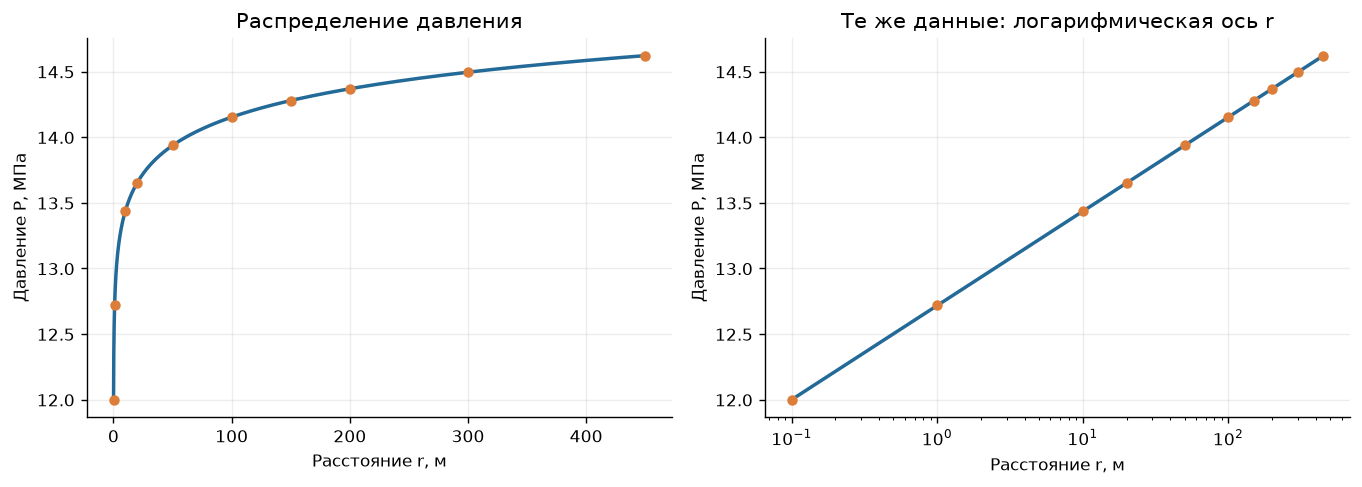

**Ответ.** Давление на контуре питания **$P_к=14.6214$ МПа**. На стенке скважины $P=12$ МПа; давление возрастает с расстоянием до контура.

In [5]:
mu_37 = 2.5 * MPAS
k_37 = 0.19 * MICRON2
rk_37, rc_37, h_37 = 450.0, 10 * CM, 14.0
Pc_37 = 12 * MPA
Q_37 = 180 / SECOND_PER_DAY
Pk_37 = Pc_37 + Q_37 * mu_37 / (2 * np.pi * k_37 * h_37) * np.log(rk_37 / rc_37)

def pressure_37(r):
    return Pc_37 + (Pk_37 - Pc_37) / np.log(rk_37 / rc_37) * np.log(np.asarray(r) / rc_37)

r_table_37 = np.array([0.1, 1, 10, 20, 50, 100, 150, 200, 300, 450])
table_37 = pd.DataFrame({'r, м': r_table_37, 'P, МПа': pressure_37(r_table_37) / MPA})
display(table_37)
r_plot_37 = np.geomspace(rc_37, rk_37, 700)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
for ax in axes:
    ax.plot(r_plot_37, pressure_37(r_plot_37)/MPA, color='#236A98', linewidth=2)
    ax.scatter(r_table_37, table_37['P, МПа'], color='#DC7D39', s=25, zorder=3)
    ax.set(xlabel='Расстояние r, м', ylabel='Давление P, МПа')
axes[0].set_title('Распределение давления')
axes[1].set_xscale('log')
axes[1].set_title('Те же данные: логарифмическая ось r')
fig.tight_layout()
plt.show()
results['3.7'] = f'Pк = {Pk_37/MPA:.4f} МПа; график P(r)'
answer(f'Давление на контуре питания **$P_к={Pk_37/MPA:.4f}$ МПа**. '
       f'На стенке скважины $P={Pc_37/MPA:g}$ МПа; давление возрастает с расстоянием до контура.')

## 4.1. Индикаторная диаграмма и параметры пласта

**Дано:** $P_{\mathrm к}=21$ МПа; $r_{\mathrm к}=330$ м; $r_{\mathrm с}=10$ см;
$h=16$ м; $\mu=19{,}3$ мПа·с (табл. П 4.1, стр. 77).

| Режим | $Q$, м³/сут | $P_{\mathrm с}$, МПа |
|:--|--:|--:|
| 1 | 22,5 | 19,2 |
| 2 | 33,8 | 18,3 |
| 3 | 43,8 | 17,5 |

> «График зависимости дебита от депрессии называют индикаторной диаграммой» (стр. 13).

$$\Delta P=P_{\mathrm к}-P_{\mathrm с},\qquad
K_{\mathrm{прод}}=\frac{Q}{\Delta P}.\qquad (19)$$
$$k=\frac{K_{\mathrm{прод}}\mu\ln(r_{\mathrm к}/r_{\mathrm с})}{2\pi h}.\qquad (27)$$

Как в книге, по горизонтали откладываем $Q$, по вертикали — $\Delta P$.
Основной расчёт выполняем по первой точке, лежащей на практически прямой диаграмме.
Дополнительно проверяем все три режима и аппроксимацию $Q=K\Delta P$ через начало координат:
$K=\sum\Delta P_i Q_i/\sum\Delta P_i^2$.
Небольшое различие отношений $Q/\Delta P$ связано с округлением табличных расходов.

,Режим,"Q, м³/сут","Pс, МПа","ΔP, МПа","K, м³/(сут·МПа)"
0,1,22.5,19.2,1.8,12.5
1,2,33.8,18.3,2.7,12.5185
2,3,43.8,17.5,3.5,12.5143


,Величина / способ,Значение,Единица
0,По первой точке: K,12.5,м³/(сут·МПа)
1,По первой точке: K в СИ,1.44676e-10,м³/(с·Па)
2,По первой точке: k,0.225024,мкм²
3,МНК через начало: K,12.5136,м³/(сут·МПа)
4,МНК через начало: k,0.225269,мкм²


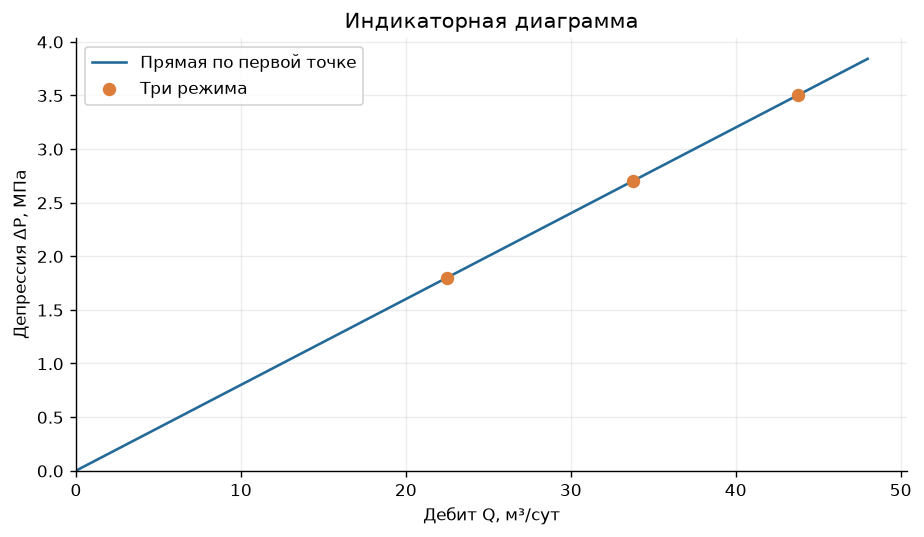

**Ответ.** **$K_{прод}=12.500$ м³/(сут·МПа), $k=0.22502$ мкм²**. Проверка по трём точкам: $k=0.22527$ мкм²; расхождение 0.109 %. Диаграмма практически линейна.

In [6]:
Pk_41 = 21 * MPA
rk_41, rc_41, h_41 = 330.0, 10 * CM, 16.0
mu_41 = 19.3 * MPAS
Q_day_41 = np.array([22.5, 33.8, 43.8])
Pc_mpa_41 = np.array([19.2, 18.3, 17.5])
dP_mpa_41 = Pk_41/MPA - Pc_mpa_41
K_modes_41 = Q_day_41 / dP_mpa_41
K_book_41 = K_modes_41[0]
K_fit_41 = np.dot(dP_mpa_41, Q_day_41) / np.dot(dP_mpa_41, dP_mpa_41)
K_si_41 = K_book_41 / (SECOND_PER_DAY * MPA)
k_41 = K_si_41 * mu_41 * np.log(rk_41/rc_41) / (2*np.pi*h_41)
k_fit_41 = K_fit_41/(SECOND_PER_DAY*MPA)*mu_41*np.log(rk_41/rc_41)/(2*np.pi*h_41)
display(pd.DataFrame({
    'Режим': [1, 2, 3], 'Q, м³/сут': Q_day_41,
    'Pс, МПа': Pc_mpa_41, 'ΔP, МПа': dP_mpa_41,
    'K, м³/(сут·МПа)': K_modes_41,
}))
show_table([
    ['По первой точке: K', K_book_41, 'м³/(сут·МПа)'],
    ['По первой точке: K в СИ', K_si_41, 'м³/(с·Па)'],
    ['По первой точке: k', k_41 / MICRON2, 'мкм²'],
    ['МНК через начало: K', K_fit_41, 'м³/(сут·МПа)'],
    ['МНК через начало: k', k_fit_41 / MICRON2, 'мкм²'],
], ['Величина / способ', 'Значение', 'Единица'])
fig, ax = plt.subplots(figsize=(7.5, 4.4))
q_grid_41 = np.linspace(0, 48, 200)
ax.plot(q_grid_41, q_grid_41/K_book_41, label='Прямая по первой точке', color='#236A98')
ax.scatter(Q_day_41, dP_mpa_41, color='#DC7D39', s=45, label='Три режима', zorder=3)
ax.set(xlabel='Дебит Q, м³/сут', ylabel='Депрессия ΔP, МПа', title='Индикаторная диаграмма')
ax.set_xlim(left=0); ax.set_ylim(bottom=0); ax.legend()
fig.tight_layout(); plt.show()
results['4.1'] = f'K = {K_book_41:.3f} м³/(сут·МПа); k = {k_41/MICRON2:.5f} мкм²'
answer(f'**$K_{{прод}}={K_book_41:.3f}$ м³/(сут·МПа), $k={k_41/MICRON2:.5f}$ мкм²**. '
       f'Проверка по трём точкам: $k={k_fit_41/MICRON2:.5f}$ мкм²; расхождение '
       f'{100*abs(k_fit_41/k_41-1):.3f} %. Диаграмма практически линейна.')

## 5.3. Объёмный и массовый дебиты газовой скважины

**Дано:** $h=7$ м; $k=0{,}3$ мкм²; $\mu=0{,}015$ мПа·с;
$\rho_0=0{,}65$ кг/м³; $r_{\mathrm с}=10$ см; $r_{\mathrm к}=500$ м;
$P_{\mathrm с}=5$ МПа; $P_{\mathrm к}=10$ МПа (табл. П 5.3, стр. 81).

> «Объемный расход, приведенный к атмосферному давлению» (стр. 18).

$$Q_{\mathrm{ат}}=\frac{\pi kh}{\mu P_{\mathrm{ат}}}
\frac{P_{\mathrm к}^2-P_{\mathrm с}^2}{\ln(r_{\mathrm к}/r_{\mathrm с})}.\qquad (41)$$
$$Q_{\mathrm м}=\rho_{\mathrm{ат}}Q_{\mathrm{ат}}.\qquad (40),(41)$$

Как в примере на стр. 48, принимаем $P_{\mathrm{ат}}=0{,}1$ МПа и используем
табличную плотность как плотность газа при опорных условиях: $\rho_{\mathrm{ат}}=\rho_0$.
Давления в газовой формуле рассматриваются как абсолютные. Поправки на температуру и сверхсжимаемость не вводятся: это модель идеального газа из пособия.

In [7]:
h_53, k_53, mu_53 = 7.0, 0.3*MICRON2, 0.015*MPAS
rho_at_53 = 0.65
rc_53, rk_53 = 10*CM, 500.0
Pc_53, Pk_53 = 5*MPA, 10*MPA
Q_at_53 = np.pi*k_53*h_53/(mu_53*P_ATM_BOOK)*(Pk_53**2-Pc_53**2)/np.log(rk_53/rc_53)
Q_mass_53 = rho_at_53 * Q_at_53
show_table([
    ['Объёмный дебит при Pат', Q_at_53, 'м³/с'],
    ['Объёмный дебит при Pат', Q_at_53*SECOND_PER_DAY, 'м³/сут'],
    ['Массовый дебит', Q_mass_53, 'кг/с'],
    ['Массовый дебит', Q_mass_53*SECOND_PER_DAY/1000, 'т/сут'],
], ['Величина', 'Значение', 'Единица'])
results['5.3'] = f'Qат = {Q_at_53*SECOND_PER_DAY:,.0f} м³/сут; Qм = {Q_mass_53*SECOND_PER_DAY/1000:,.2f} т/сут'
answer(f'**$Q_{{ат}}={Q_at_53*SECOND_PER_DAY:,.0f}$ м³/сут**, '
       f'**$Q_м={Q_mass_53*SECOND_PER_DAY/1000:,.2f}$ т/сут** '
       f'({Q_mass_53:.4f} кг/с).')

,Величина,Значение,Единица
0,Объёмный дебит при Pат,38.7296,м³/с
1,Объёмный дебит при Pат,3.34623e+06,м³/сут
2,Массовый дебит,25.1742,кг/с
3,Массовый дебит,2175.05,т/сут


**Ответ.** **$Q_{ат}=3,346,235$ м³/сут**, **$Q_м=2,175.05$ т/сут** (25.1742 кг/с).

## 6.1. Фазовые проницаемости нефти и газа

**Дано:** нефтенасыщенность $\sigma=70\%$, абсолютная проницаемость $k=0{,}5$ мкм²
(табл. П 6.1, стр. 82).

> «Отношение фазовой и абсолютной проницаемостей горной породы называется относительной проницаемостью» (стр. 20).

$$\overline k_i=\frac{k_i}{k}.\qquad (48)$$
Отсюда, как в примере на стр. 48:
$$k_{\mathrm н}=\overline k_{\mathrm н}k,\qquad k_{\mathrm г}=\overline k_{\mathrm г}k.$$

На рис. 1П при $\sigma=70\%$ считываются примерно **32% для жидкости (нефти)** и **11% для газа**:
$\overline k_{\mathrm н}\approx0{,}32$, $\overline k_{\mathrm г}\approx0{,}11$.
Скан не задаёт точные табличные значения; для оценки чувствительности принимаем погрешность считывания около ±2 процентных пунктов (±0,02 в долях). Это оценка чтения графика, а не статистический доверительный интервал.

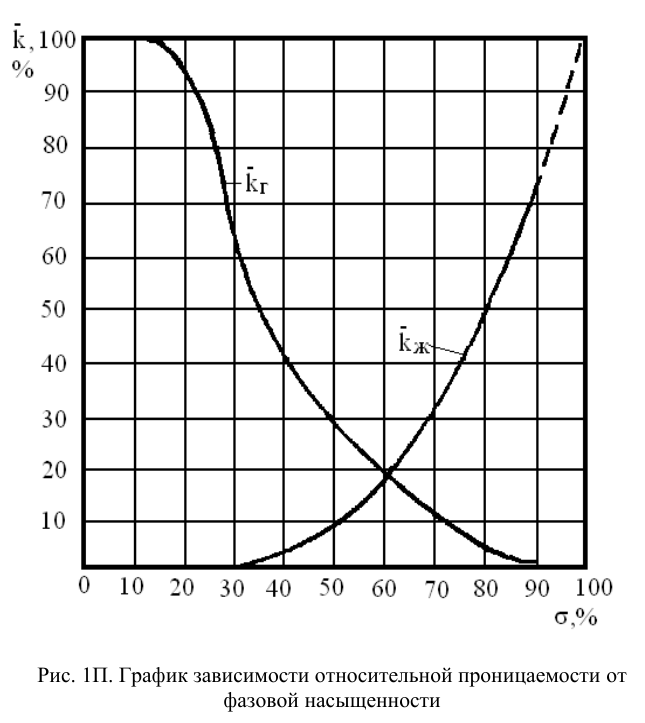

*Рис. 1П из пособия, стр. 100 PDF. По вертикали относительная проницаемость в процентах.*

,Фаза,"Относительная проницаемость, доля","Фазовая проницаемость, мкм²","Нижняя оценка, мкм²","Верхняя оценка, мкм²"
0,Нефть,0.32,0.16,0.15,0.17
1,Газ,0.11,0.055,0.045,0.065


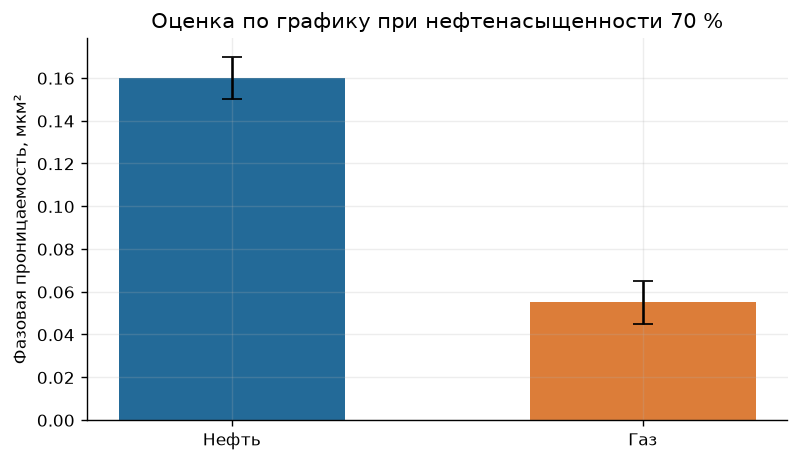

**Ответ.** По графику **$k_н\approx0.160$ мкм²**, **$k_г\approx0.055$ мкм²**. Ориентировочная неопределённость считывания каждой оценки ±0.010 мкм².

In [8]:
sigma_61 = 70.0
k_absolute_61 = 0.5 * MICRON2
kr_oil_61, kr_gas_61 = 0.32, 0.11
reading_error_61 = 0.02
k_oil_61 = kr_oil_61 * k_absolute_61
k_gas_61 = kr_gas_61 * k_absolute_61
display(pd.DataFrame({
    'Фаза': ['Нефть', 'Газ'],
    'Относительная проницаемость, доля': [kr_oil_61, kr_gas_61],
    'Фазовая проницаемость, мкм²': np.array([k_oil_61, k_gas_61])/MICRON2,
    'Нижняя оценка, мкм²': (np.array([kr_oil_61,kr_gas_61])-reading_error_61)*k_absolute_61/MICRON2,
    'Верхняя оценка, мкм²': (np.array([kr_oil_61,kr_gas_61])+reading_error_61)*k_absolute_61/MICRON2,
}))
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(['Нефть', 'Газ'], np.array([k_oil_61,k_gas_61])/MICRON2,
       yerr=reading_error_61*k_absolute_61/MICRON2, capsize=6, color=['#236A98','#DC7D39'], width=0.55)
ax.set(ylabel='Фазовая проницаемость, мкм²', title='Оценка по графику при нефтенасыщенности 70 %')
fig.tight_layout(); plt.show()
results['6.1'] = f'kн ≈ {k_oil_61/MICRON2:.3f}; kг ≈ {k_gas_61/MICRON2:.3f} мкм² (график)'
answer(f'По графику **$k_н\\approx{k_oil_61/MICRON2:.3f}$ мкм²**, '
       f'**$k_г\\approx{k_gas_61/MICRON2:.3f}$ мкм²**. '
       f'Ориентировочная неопределённость считывания каждой оценки ±{reading_error_61*k_absolute_61/MICRON2:.3f} мкм².')

## 7.1. Дебит несовершенной по степени вскрытия скважины

**Дано:** $P_{\mathrm к}=16$ МПа; $P_{\mathrm с}=13$ МПа; $r_{\mathrm к}=450$ м;
$h=14$ м; $k=0{,}28$ мкм²; $\mu=5{,}5$ мПа·с; $r_{\mathrm с}=10$ см; $b=6$ м
(табл. П 7.1, стр. 84).

> «Дебит гидродинамически несовершенной скважины можно определить по формуле» (стр. 24).

$$Q=\frac{2\pi kh}{\mu}
\frac{P_{\mathrm к}-P_{\mathrm с}}{\ln(r_{\mathrm к}/r_{\mathrm с})+C}.\qquad (59)$$

Как непосредственно в примере 7.1 на стр. 48–49, коэффициент несовершенства по степени вскрытия используем в знаменателе (59).
Вычисляем $\delta=b/h$, $D=2r_{\mathrm с}$, $a=h/D$.
Для воспроизводимого численного значения используем аппроксимацию книги:

$$C_1=7{,}86\left(0{,}3\ln^2\delta-0{,}25\ln\delta\right)
\left(0{,}03+0{,}14\ln\frac hD+0{,}04\ln^2\frac hD\right).\qquad (61)$$

В (61) $\delta$ подставляется **долей единицы**. На графике используется $100\delta$ в процентах.
Для проверки по графику при $100\delta\approx42{,}86\%$ и $a=70$ получается приблизительно $C_1\approx4{,}7$; чтение графика имеет ограниченную точность.

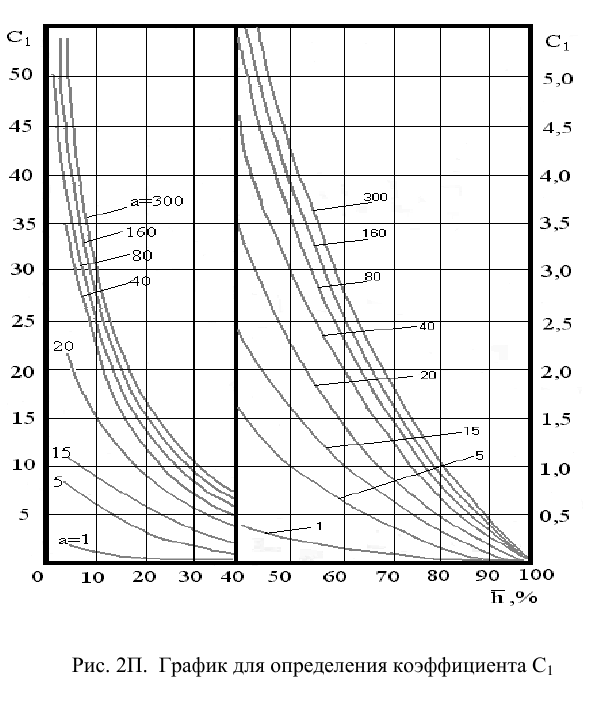

*Рис. 2П из пособия, стр. 100 PDF. При вскрытии свыше 40 % используется правая вертикальная шкала C₁.*

In [9]:
Pk_71, Pc_71 = 16*MPA, 13*MPA
rk_71, rc_71, h_71, b_71 = 450.0, 10*CM, 14.0, 6.0
k_71, mu_71 = 0.28*MICRON2, 5.5*MPAS
delta_71, diameter_71 = b_71/h_71, 2*rc_71
a_71 = h_71/diameter_71
log_delta_71, log_a_71 = np.log(delta_71), np.log(a_71)
C1_71 = 7.86*(0.3*log_delta_71**2-0.25*log_delta_71)*(0.03+0.14*log_a_71+0.04*log_a_71**2)

def flow_71(C):
    return 2*np.pi*k_71*h_71/mu_71*(Pk_71-Pc_71)/(np.log(rk_71/rc_71)+C)

Q_71 = flow_71(C1_71)
Q_perfect_71 = flow_71(0)
C_graph_71 = 4.7
show_table([
    ['Доля вскрытия δ = b/h', delta_71, 'доля'],
    ['Относительное вскрытие', 100*delta_71, '%'],
    ['a = h/D', a_71, 'безразмерное'],
    ['C₁ по формуле (61)', C1_71, 'безразмерное'],
    ['Q по (59), (61)', Q_71*SECOND_PER_DAY, 'м³/сут'],
    ['Q при C₁ ≈ 4,7 по графику', flow_71(C_graph_71)*SECOND_PER_DAY, 'м³/сут'],
    ['Q совершенной скважины, C = 0', Q_perfect_71*SECOND_PER_DAY, 'м³/сут'],
], ['Величина', 'Значение', 'Единица'])
results['7.1'] = f'Q ≈ {Q_71*SECOND_PER_DAY:.2f} м³/сут; C₁ ≈ {C1_71:.3f} по (61)'
answer(f'По аппроксимации (61) **$C_1={C1_71:.3f}$**, '
       f'**$Q\\approx{Q_71*SECOND_PER_DAY:.2f}$ м³/сут**. '
       f'По непосредственному чтению графика $Q\\approx{flow_71(C_graph_71)*SECOND_PER_DAY:.1f}$ м³/сут. '
       f'Дебит составляет {100*Q_71/Q_perfect_71:.1f} % от дебита совершенной скважины.')

,Величина,Значение,Единица
0,Доля вскрытия δ = b/h,0.428571,доля
1,Относительное вскрытие,42.8571,%
2,a = h/D,70,безразмерное
3,C₁ по формуле (61),4.52218,безразмерное
4,"Q по (59), (61)",89.7439,м³/сут
5,"Q при C₁ ≈ 4,7 по графику",88.5268,м³/сут
6,"Q совершенной скважины, C = 0",137.99,м³/сут


**Ответ.** По аппроксимации (61) **$C_1=4.522$**, **$Q\approx89.74$ м³/сут**. По непосредственному чтению графика $Q\approx88.5$ м³/сут. Дебит составляет 65.0 % от дебита совершенной скважины.

## 8.1. Гидропроводность и проницаемость по восстановлению давления

**Дано:** $h=9$ м; $\mu=1{,}9$ мПа·с; $Q=70$ м³/сут. Время и давление взяты
из столбцов «5 вариант» табл. П 8.2 (стр. 87); параметры — из П 8.1 на той же странице.

В примере приращение давления: $\Delta P=P_t-P_{t=0}$.

$$\Delta P_{\mathrm с}=A+B\ln t.\qquad (82)$$

> «Формула (82) является уравнением прямой линии в координатах ΔP, ln t с угловым коэффициентом В и отсекаемым на оси ординат отрезком А» (стр. 28).

$$B=\frac{y_2-y_1}{x_2-x_1},\quad x=\ln t,\quad y=\Delta P;\qquad (83)$$
$$\varepsilon=\frac{q}{4\pi B},\qquad k=\frac{\varepsilon\mu}{h}.\qquad (84),(85)$$

Точку $t=0$ сохраняем в исходной таблице и на графике $P(t)$, но исключаем из $\ln t$.
Для перевода в СИ давление берём в Па, время — в секундах.

In [10]:
h_81, mu_81, Q_81 = 9.0, 1.9*MPAS, 70/SECOND_PER_DAY
t_min_81 = np.array([0,26,80,140,200,300,420,570,750,1020,1320,1560,1800,2040,2280,2520,2760,3660,3960,4200,4320,4500], dtype=float)
P_mpa_81 = np.array([2.627,2.883,3.839,4.876,5.852,7.189,8.224,8.918,9.417,9.739,9.895,9.965,9.990,10.023,10.042,10.054,10.062,10.065,10.067,10.069,10.070,10.072])
t_sec_81 = 60*t_min_81
dP_pa_81 = (P_mpa_81-P_mpa_81[0])*MPA
ln_t_81 = np.full_like(t_min_81, np.nan)
ln_t_81[t_min_81>0] = np.log(t_sec_81[t_min_81>0])
table_81 = pd.DataFrame({
    't, мин': t_min_81, 'P, МПа': P_mpa_81,
    'ΔP, МПа': dP_pa_81/MPA, 'ln(t / 1 с)': ln_t_81,
})
display(table_81)

,"t, мин","P, МПа","ΔP, МПа",ln(t / 1 с)
0,0,2.627,0,NaN
1,26,2.883,0.256,7.35244
2,80,3.839,1.212,8.47637
3,140,4.876,2.249,9.03599
4,200,5.852,3.225,9.39266
5,300,7.189,4.562,9.79813
6,420,8.224,5.597,10.1346
7,570,8.918,6.291,10.44
8,750,9.417,6.79,10.7144
9,1020,9.739,7.112,11.0219


**Выбор участка.** Начальная часть кривой заметно искривлена. Для основного расчёта принят последний участок
**3660–4500 мин, пять точек**. Прямую проводим через его крайние точки — это способ из формулы (83).
Регрессия пяти точек приведена как проверка.
Поскольку поздние давления округлены до 0,001 МПа, выбор участка заметно влияет на $k$;
ниже показаны несколько альтернативных границ. Оценка не должна восприниматься как точное лабораторное измерение.

,Величина,Значение,Единица
0,Число точек выбранного участка,5,шт.
1,Уклон B по крайним точкам,33879.6,Па на единицу ln(t)
2,Гидропроводность ε,1.90299e-09,м³/(Па·с)
3,Проницаемость k,4.01742e-13,м²
4,Проницаемость k,0.401742,мкм²
5,Проверка: k по МНК пяти точек,0.409516,мкм²
6,R² регрессии выбранного участка,0.982975,безразмерное


,"Начало, мин","Конец, мин",Точек,"B, МПа","k по концам, мкм²",R² МНК
0,2040,4500,9,0.0619369,0.219754,0.82164
1,2280,4500,8,0.044124,0.308468,0.865929
2,2520,4500,7,0.0310442,0.438435,0.91427
3,2760,4500,6,0.0204563,0.665362,0.899419
4,3660,4500,5,0.0338796,0.401742,0.982975
5,3960,4500,4,0.0391134,0.347984,0.990238


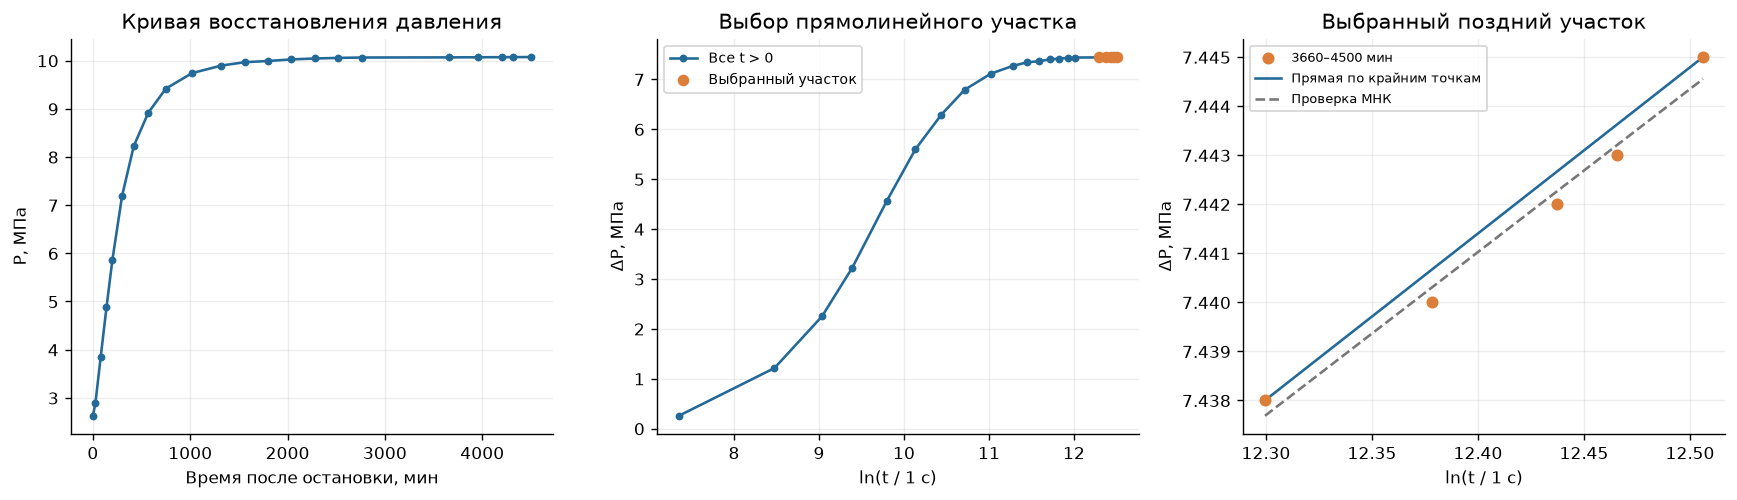

**Ответ.** Для участка 3660–4500 мин **$\varepsilon\approx1.9030e-09$ м³/(Па·с)**, **$k\approx0.402$ мкм²**. Регрессия тех же пяти точек даёт 0.410 мкм². Результат зависит от выбора позднего участка; чувствительность приведена в таблице.

In [11]:
mask_81 = t_min_81 >= 3660
x_fit_81, y_fit_81 = ln_t_81[mask_81], dP_pa_81[mask_81]
B_81 = (y_fit_81[-1]-y_fit_81[0])/(x_fit_81[-1]-x_fit_81[0])
A_81 = y_fit_81[0]-B_81*x_fit_81[0]
eps_81 = Q_81/(4*np.pi*B_81)
k_81 = eps_81*mu_81/h_81
reg_81 = linregress(x_fit_81,y_fit_81)
k_ols_81 = Q_81/(4*np.pi*reg_81.slope)*mu_81/h_81
show_table([
    ['Число точек выбранного участка', int(mask_81.sum()), 'шт.'],
    ['Уклон B по крайним точкам', B_81, 'Па на единицу ln(t)'],
    ['Гидропроводность ε', eps_81, 'м³/(Па·с)'],
    ['Проницаемость k', k_81, 'м²'],
    ['Проницаемость k', k_81/MICRON2, 'мкм²'],
    ['Проверка: k по МНК пяти точек', k_ols_81/MICRON2, 'мкм²'],
    ['R² регрессии выбранного участка', reg_81.rvalue**2, 'безразмерное'],
], ['Величина', 'Значение', 'Единица'])

window_rows_81 = []
for start in [2040,2280,2520,2760,3660,3960]:
    sel = t_min_81>=start
    x, y = ln_t_81[sel],dP_pa_81[sel]
    slope = (y[-1]-y[0])/(x[-1]-x[0])
    fit = linregress(x,y)
    window_rows_81.append([start,4500,int(sel.sum()),slope/MPA,
                           Q_81/(4*np.pi*slope)*mu_81/h_81/MICRON2,fit.rvalue**2])
display(pd.DataFrame(window_rows_81, columns=['Начало, мин','Конец, мин','Точек','B, МПа','k по концам, мкм²','R² МНК']))

fig, axes = plt.subplots(1,3,figsize=(14,4.1))
axes[0].plot(t_min_81,P_mpa_81,'o-',color='#236A98',markersize=3.5)
axes[0].set(xlabel='Время после остановки, мин',ylabel='P, МПа',title='Кривая восстановления давления')
axes[1].plot(ln_t_81[1:],dP_pa_81[1:]/MPA,'o-',color='#236A98',markersize=3.5,label='Все t > 0')
axes[1].scatter(x_fit_81,y_fit_81/MPA,color='#DC7D39',s=32,zorder=4,label='Выбранный участок')
axes[1].set(xlabel='ln(t / 1 с)',ylabel='ΔP, МПа',title='Выбор прямолинейного участка')
axes[1].legend(fontsize=8)
axes[2].scatter(x_fit_81,y_fit_81/MPA,color='#DC7D39',s=35,label='3660–4500 мин',zorder=4)
xs = np.linspace(x_fit_81[0],x_fit_81[-1],100)
axes[2].plot(xs,(A_81+B_81*xs)/MPA,color='#236A98',label='Прямая по крайним точкам')
axes[2].plot(xs,(reg_81.intercept+reg_81.slope*xs)/MPA,'--',color='#777777',label='Проверка МНК')
axes[2].set(xlabel='ln(t / 1 с)',ylabel='ΔP, МПа',title='Выбранный поздний участок')
axes[2].legend(fontsize=7.5)
fig.tight_layout(); plt.show()
results['8.1'] = f'ε ≈ {eps_81:.3e} м³/(Па·с); k ≈ {k_81/MICRON2:.3f} мкм²'
answer(f'Для участка 3660–4500 мин **$\\varepsilon\\approx{eps_81:.4e}$ м³/(Па·с)**, '
       f'**$k\\approx{k_81/MICRON2:.3f}$ мкм²**. '
       f'Регрессия тех же пяти точек даёт {k_ols_81/MICRON2:.3f} мкм². '
       'Результат зависит от выбора позднего участка; чувствительность приведена в таблице.')

## 9.1. Давление в точке А при переменных дебитах двух скважин

**Дано:** $h=22$ м; $k=0{,}44$ мкм²; $m=22\%$; $\beta_{\mathrm п}=1{,}8\cdot10^{-10}$ Па⁻¹;
$\beta_{\mathrm ж}=7\cdot10^{-10}$ Па⁻¹; $P_0=17$ МПа; $\mu=1$ мПа·с
(табл. П 9.3, стр. 96; вязкость — условие задачи на стр. 43).

Координаты (табл. П 9.2, стр. 95): $A=(0,0)$ м, добывающая $(200,800)$ м,
нагнетательная $(600,1000)$ м. Первую пару координат $(x_0,y_0)$ принимаем за точку А.

Расписания из табл. П 9.1 (стр. 94):

| Скважина | Расходы по этапам, м³/сут | Длительности этапов, сут |
|:--|:--|:--|
| Добывающая | 500; 100; 300 | 300; 200; 300 |
| Нагнетательная | 400; 500 | 250; 550 |

Оба расписания охватывают **800 суток**. По аналогии с примером расчёт выполняем в конце этих интервалов.

$$\chi=\frac{k}{\mu(m\beta_{\mathrm ж}+\beta_{\mathrm п})}.\qquad (70)$$

> «Дебиты фиктивных скважин определяются как разница между последующим и предыдущим дебитами реальной скважины, а продолжительность работы таких скважин определяется с момента изменения дебита реальной скважины до окончания ее работы» (стр. 27).

$$\Delta q_i=q_i-q_{i-1},\qquad q_0=0,$$
$$\Delta P_i=\frac{\mu\Delta q_i}{4\pi kh}
E_1\!\left(\frac{r^2}{4\chi t_i}\right),\qquad
E_1(x)=-\operatorname{Ei}(-x).\qquad (79)$$

Для сравнения с вычислениями примера (стр. 51–52) используем также его логарифмическую форму:
$$\Delta P_{i,\log}=\frac{\mu\Delta q_i}{4\pi kh}
\ln\frac{2{,}246\chi t_i}{r^2}.\qquad (77)$$

$$r=\sqrt{(\Delta x)^2+(\Delta y)^2},\qquad
P_A=P_0-\sum\Delta P_{\mathrm{доб},i}+\sum\Delta P_{\mathrm{нагн},i}.$$

Положительные расходы задаются отдельно для добычи и закачки; знак их воздействия на давление учитывается в последней формуле.
Отрицательное изменение дебита фиктивной скважины сохраняет свой знак при суммировании.

In [12]:
h_91, k_91, m_91 = 22.0, 0.44*MICRON2, 0.22
beta_rock_91, beta_liquid_91 = 1.8e-10, 7e-10
mu_91, P0_91 = 1*MPAS, 17*MPA
chi_91 = k_91/(mu_91*(m_91*beta_liquid_91+beta_rock_91))
A_xy_91 = np.array([0.0,0.0])
prod_xy_91, inj_xy_91 = np.array([200.0,800.0]),np.array([600.0,1000.0])
r_prod_91, r_inj_91 = np.linalg.norm(prod_xy_91-A_xy_91),np.linalg.norm(inj_xy_91-A_xy_91)
prod_rates_91, prod_durations_91 = np.array([500.,100.,300.]),np.array([300.,200.,300.])
inj_rates_91, inj_durations_91 = np.array([400.,500.]),np.array([250.,550.])
T_day_91 = prod_durations_91.sum()

def well_components_91(rates_day,durations_day,distance,label):
    starts = np.r_[0,np.cumsum(durations_day)[:-1]]
    ages = T_day_91-starts
    increments = np.diff(np.r_[0,rates_day])
    arg = distance**2/(4*chi_91*ages*SECOND_PER_DAY)
    factor = mu_91/(4*np.pi*k_91*h_91)*increments/SECOND_PER_DAY
    return pd.DataFrame({
        'Скважина': label,'№ фиктивной':np.arange(1,len(rates_day)+1),
        'Начало этапа, сут':starts,'Δq, м³/сут':increments,'Время работы, сут':ages,
        'r, м':distance,'x = r²/(4χt)':arg,
        'ΔP точно, Па':factor*exp1(arg),
        'ΔP лог., Па':factor*np.log(2.246*chi_91*ages*SECOND_PER_DAY/distance**2),
    })

components_prod_91 = well_components_91(prod_rates_91,prod_durations_91,r_prod_91,'Добывающая')
components_inj_91 = well_components_91(inj_rates_91,inj_durations_91,r_inj_91,'Нагнетательная')
components_91 = pd.concat([components_prod_91,components_inj_91],ignore_index=True)
display(components_91)
dP_prod_91 = components_prod_91['ΔP точно, Па'].sum()
dP_inj_91 = components_inj_91['ΔP точно, Па'].sum()
dP_prod_log_91 = components_prod_91['ΔP лог., Па'].sum()
dP_inj_log_91 = components_inj_91['ΔP лог., Па'].sum()
PA_91 = P0_91-dP_prod_91+dP_inj_91
PA_log_91 = P0_91-dP_prod_log_91+dP_inj_log_91
show_table([
    ['Пьезопроводность χ',chi_91,'м²/с'],
    ['Расстояние до добывающей',r_prod_91,'м'],
    ['Расстояние до нагнетательной',r_inj_91,'м'],
    ['Понижение от добычи, точное',dP_prod_91/MPA,'МПа'],
    ['Повышение от закачки, точное',dP_inj_91/MPA,'МПа'],
    ['P_A по логарифмической форме книги',PA_log_91/MPA,'МПа'],
    ['P_A по точной экспоненциальной функции',PA_91/MPA,'МПа'],
    ['Разность точного и логарифмического ответа',PA_91-PA_log_91,'Па'],
],['Величина','Значение','Единица'])

,Скважина,№ фиктивной,"Начало этапа, сут","Δq, м³/сут","Время работы, сут","r, м",x = r²/(4χt),"ΔP точно, Па","ΔP лог., Па"
0,Добывающая,1,0,500,800,824.621,0.00186698,271557,271472
1,Добывающая,2,300,-400,500,824.621,0.00298716,-199400,-199290
2,Добывающая,3,500,200,300,824.621,0.00497861,90017.2,89923.9
3,Нагнетательная,1,0,400,800,1166.19,0.00373395,190936,190797
4,Нагнетательная,2,250,100,550,1166.19,0.00543121,44185,44134.1


,Величина,Значение,Единица
0,Пьезопроводность χ,1.31737,м²/с
1,Расстояние до добывающей,824.621,м
2,Расстояние до нагнетательной,1166.19,м
3,"Понижение от добычи, точное",0.162174,МПа
4,"Повышение от закачки, точное",0.235121,МПа
5,P_A по логарифмической форме книги,17.0728,МПа
6,P_A по точной экспоненциальной функции,17.0729,МПа
7,Разность точного и логарифмического ответа,122.416,Па


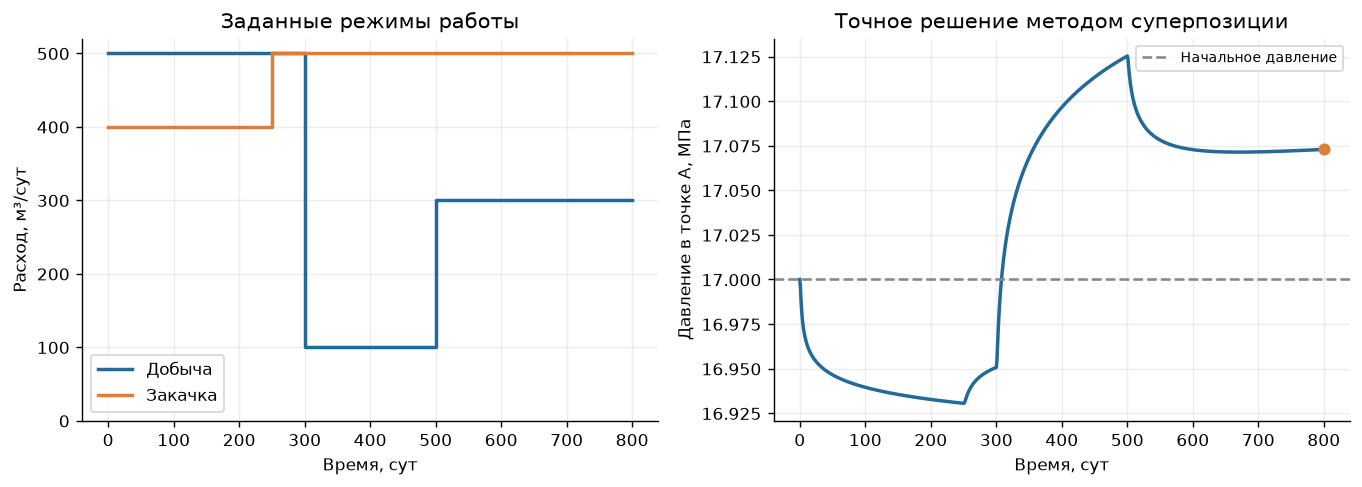

**Ответ.** К концу **800 суток** по логарифмической форме книги **$P_A\approx17.072825$ МПа**. Точная проверка: **17.072947 МПа**; разность 122.4 Па. Суммарное повышение от закачки немного превышает понижение от добычи.

In [13]:
def pressure_history_91(days):
    days = np.atleast_1d(np.asarray(days,dtype=float))
    pressure = np.full(days.shape,P0_91,dtype=float)
    for rates,durations,radius,sign in [
        (prod_rates_91,prod_durations_91,r_prod_91,-1),
        (inj_rates_91,inj_durations_91,r_inj_91,+1),
    ]:
        starts = np.r_[0,np.cumsum(durations)[:-1]]
        increments = np.diff(np.r_[0,rates])
        for start,increment in zip(starts,increments):
            active = days>start
            age = (days[active]-start)*SECOND_PER_DAY
            pressure[active] += sign*mu_91/(4*np.pi*k_91*h_91)*increment/SECOND_PER_DAY*exp1(radius**2/(4*chi_91*age))
    return pressure

fig, axes = plt.subplots(1,2,figsize=(11,4))
for rates,durations,label,color in [
    (prod_rates_91,prod_durations_91,'Добыча','#236A98'),
    (inj_rates_91,inj_durations_91,'Закачка','#DC7D39'),
]:
    edges = np.r_[0,np.cumsum(durations)]
    axes[0].step(edges,np.r_[rates,rates[-1]],where='post',label=label,color=color,linewidth=2)
axes[0].set(xlabel='Время, сут',ylabel='Расход, м³/сут',title='Заданные режимы работы')
axes[0].set_ylim(bottom=0);axes[0].legend()
t_history_91 = np.linspace(0,T_day_91,801)
axes[1].plot(t_history_91,pressure_history_91(t_history_91)/MPA,color='#236A98',linewidth=2)
axes[1].axhline(P0_91/MPA,color='#888888',linestyle='--',label='Начальное давление')
axes[1].scatter([T_day_91],[PA_91/MPA],color='#DC7D39',s=35,zorder=3)
axes[1].set(xlabel='Время, сут',ylabel='Давление в точке А, МПа',title='Точное решение методом суперпозиции')
axes[1].legend(fontsize=8)
fig.tight_layout();plt.show()
results['9.1'] = f'P_A ≈ {PA_log_91/MPA:.6f} МПа (книга); {PA_91/MPA:.6f} МПа (E₁)'
answer(f'К концу **{T_day_91:g} суток** по логарифмической форме книги '
       f'**$P_A\\approx{PA_log_91/MPA:.6f}$ МПа**. '
       f'Точная проверка: **{PA_91/MPA:.6f} МПа**; разность {PA_91-PA_log_91:.1f} Па. '
       'Суммарное повышение от закачки немного превышает понижение от добычи.')

## 10.1. Дебит скважины в пласте из трёх пропластков

**Дано:** $h_1=1{,}8$ м, $h_2=4{,}0$ м, $h_3=3{,}4$ м;
$k_1=0{,}058$ мкм², $k_2=0{,}063$ мкм², $k_3=0{,}031$ мкм²;
$P_{\mathrm к}=18$ МПа, $P_{\mathrm с}=15$ МПа; $r_{\mathrm к}=190$ м,
$r_{\mathrm с}=10$ см; $\mu=1{,}45$ мПа·с (табл. П 10.1, стр. 97).

> «Общий расход жидкости (дебит потока) можно вычислить как сумму расходов (дебитов) в отдельных пропластках» (стр. 30).

$$Q=\sum_{i=1}^3Q_i=\left(\sum_{i=1}^3k_i h_i\right)
\frac{2\pi}{\mu}\frac{P_{\mathrm к}-P_{\mathrm с}}
{\ln(r_{\mathrm к}/r_{\mathrm с})}.\qquad (87)$$

Для каждого пропластка используются одинаковые граничные давления, вязкость и радиусы.

In [14]:
layers_h_101 = np.array([1.8,4.0,3.4])
layers_k_101 = np.array([0.058,0.063,0.031])*MICRON2
Pk_101,Pc_101 = 18*MPA,15*MPA
rk_101,rc_101,mu_101 = 190.0,10*CM,1.45*MPAS
factor_101 = 2*np.pi*(Pk_101-Pc_101)/(mu_101*np.log(rk_101/rc_101))
layers_Q_101 = layers_k_101*layers_h_101*factor_101
Q_101 = layers_Q_101.sum()
display(pd.DataFrame({
    'Пропласток':[1,2,3],'h, м':layers_h_101,'k, мкм²':layers_k_101/MICRON2,
    'kh, мкм²·м':layers_k_101*layers_h_101/MICRON2,
    'Q, м³/сут':layers_Q_101*SECOND_PER_DAY,
    'Доля общего дебита, %':100*layers_Q_101/Q_101,
}))
results['10.1'] = f'Q = {Q_101*SECOND_PER_DAY:.3f} м³/сут'
answer(f'Суммарный дебит **$Q={Q_101*SECOND_PER_DAY:.3f}$ м³/сут** '
       f'($Q={Q_101:.9f}$ м³/с). Наибольший вклад вносит второй пропласток.')

,Пропласток,"h, м","k, мкм²","kh, мкм²·м","Q, м³/сут","Доля общего дебита, %"
0,1,1.8,0.058,0.1044,15.5318,22.6072
1,2,4,0.063,0.252,37.4906,54.5691
2,3,3.4,0.031,0.1054,15.6806,22.8237


**Ответ.** Суммарный дебит **$Q=68.703$ м³/сут** ($Q=0.000795175$ м³/с). Наибольший вклад вносит второй пропласток.

## Проверки расчёта

Проверяем диапазоны физических величин, граничные значения давления, восстановление заданного дебита
по формуле Дюпюи, знаки суперпозиции и равенство суммы дебитов пропластков общему дебиту.
Дополнительно сравниваем точное и логарифмическое решения 9.1.

In [15]:
checks = {
    '1.1: пористость между 0 и 1': 0<m_11<1,
    '2.1: превышен заданный порог Щелкачёва': Re_21>1,
    '3.1: расход положителен': Q_31>0,
    '3.7: давление на стенке равно Pс': np.isclose(pressure_37(rc_37),Pc_37),
    '3.7: давление на контуре равно Pк': np.isclose(pressure_37(rk_37),Pk_37),
    '3.7: давление монотонно возрастает': np.all(np.diff(pressure_37(r_plot_37))>0),
    '3.7: обратная формула Дюпюи восстанавливает Q': np.isclose(2*np.pi*k_37*h_37/mu_37*(Pk_37-Pc_37)/np.log(rk_37/rc_37),Q_37),
    '4.1: межрежимный разброс K меньше 0,2 %': np.ptp(K_modes_41)/np.mean(K_modes_41)<0.002,
    '5.3: массовый дебит равен ρат Qат': np.isclose(Q_mass_53,rho_at_53*Q_at_53),
    '6.1: фазовые проницаемости не превышают абсолютную': 0<k_gas_61<k_absolute_61 and 0<k_oil_61<k_absolute_61,
    '7.1: несовершенство уменьшает дебит': 0<Q_71<Q_perfect_71,
    '8.1: гидропроводность и проницаемость положительны': eps_81>0 and k_81>0,
    '8.1: весь поздний участок содержит пять точек': mask_81.sum()==5,
    '9.1: расписания заканчиваются одновременно': np.isclose(prod_durations_91.sum(),inj_durations_91.sum()),
    '9.1: сумма приращений равна последнему дебиту добычи': np.isclose(components_prod_91['Δq, м³/сут'].sum(),prod_rates_91[-1]),
    '9.1: сумма приращений равна последнему дебиту закачки': np.isclose(components_inj_91['Δq, м³/сут'].sum(),inj_rates_91[-1]),
    '9.1: история в момент 0 даёт начальное давление': np.isclose(pressure_history_91([0])[0],P0_91),
    '9.1: история в момент T совпадает с конечной суммой': np.isclose(pressure_history_91([T_day_91])[0],PA_91),
    '9.1: разность E₁ и логарифмической формы меньше 0,001 МПа': abs(PA_91-PA_log_91)<0.001*MPA,
    '10.1: дебиты всех пропластков положительны': np.all(layers_Q_101>0),
    '10.1: сумма дебитов совпадает с общей формулой': np.isclose(Q_101,np.sum(layers_k_101*layers_h_101)*factor_101),
}
display(pd.DataFrame({'Проверка':list(checks),'Результат':['Пройдена' if value else 'Не пройдена' for value in checks.values()]}))
assert all(checks.values()), 'Одна из физических проверок не пройдена.'
print(f'Пройдено проверок: {len(checks)} из {len(checks)}.')

,Проверка,Результат
0,1.1: пористость между 0 и 1,Пройдена
1,2.1: превышен заданный порог Щелкачёва,Пройдена
2,3.1: расход положителен,Пройдена
3,3.7: давление на стенке равно Pс,Пройдена
4,3.7: давление на контуре равно Pк,Пройдена
5,3.7: давление монотонно возрастает,Пройдена
6,3.7: обратная формула Дюпюи восстанавливает Q,Пройдена
7,"4.1: межрежимный разброс K меньше 0,2 %",Пройдена
8,5.3: массовый дебит равен ρат Qат,Пройдена
9,6.1: фазовые проницаемости не превышают абсолю...,Пройдена


Пройдено проверок: 21 из 21.


## Итоговые ответы

Числа ниже собраны из выполненных расчётных ячеек.
Для 6.1, 7.1 и 8.1 сохранено обозначение приближённого результата.

In [16]:
summary = pd.DataFrame({'Задача':list(results),'Результат':list(results.values())})
display(summary)

,Задача,Результат
0,1.1,m = 31.947 %
1,2.1,Re = 1.4606 > 1; закон нелинейный
2,3.1,Q = 43.832 м³/сут
3,3.7,Pк = 14.6214 МПа; график P(r)
4,4.1,K = 12.500 м³/(сут·МПа); k = 0.22502 мкм²
5,5.3,"Qат = 3,346,235 м³/сут; Qм = 2,175.05 т/сут"
6,6.1,kн ≈ 0.160; kг ≈ 0.055 мкм² (график)
7,7.1,Q ≈ 89.74 м³/сут; C₁ ≈ 4.522 по (61)
8,8.1,ε ≈ 1.903e-09 м³/(Па·с); k ≈ 0.402 мкм²
9,9.1,P_A ≈ 17.072825 МПа (книга); 17.072947 МПа (E₁)


## Примечания к исходному пособию

1. В примере 2.1 (стр. 45) расход в условии 10 л/мин, а в подстановке напечатано $2\cdot10^{-3}$; здесь использованы собственные данные варианта: 2 л/мин.
2. В примере 4.1 (стр. 47) есть ошибка в переводе коэффициента продуктивности в СИ. В этом notebook перевод выполняется делением на $86400\cdot10^6$.
3. В примере 8.1 (стр. 49–50) численные значения гидропроводности в соседних действиях различаются. Здесь применены согласованные теоретические формулы (83)–(85).
4. Формула времени (80) на стр. 27 использует одно и то же обозначение для интервалов и времени работы фиктивной скважины. Здесь время вычисляется по словесному пояснению книги: $t_i=T-t_{\mathrm{начала},i}$.
5. Для 7.1 принят способ непосредственного примера 7.1: коэффициент по степени вскрытия подставляется в (59). Аппроксимация (61) заменяет чтение того же графика.
6. В оглавлении указаны неточные страницы: необходимые графики фактически находятся на стр. 100 PDF; пример 10.1 — на стр. 52.

**Воспроизводимость.** Все данные варианта, принятые соглашения и значения, снятые с графиков, явно заданы в ячейках. Результаты и рисунки сохранены в файле; повторный запуск выполняется командой Jupyter **Restart Kernel and Run All Cells**.

**Особенности расчёта:**
- 2.1: применяется критерий Щелкачёва с $\mathrm{Re}_{\mathrm{кр}}=1$, как в примере и указании на стр. 36.
- 6.1: относительные проницаемости сняты со сканированного графика, поэтому ответ приближённый.
- 7.1: основной ответ получен по аппроксимации (61); рядом приведено сравнение с графиком Щурова.
- 8.1: выбран поздний участок 3660–4500 мин; показана чувствительность результата к его границам.
- 9.1: расчёт выполнен к окончанию заданных интервалов, $T=800$ сут; проверено логарифмическое приближение книги точным решением через $E_1$.

Для повторного запуска нужны Python 3, NumPy, pandas, SciPy, Matplotlib и IPython.